In [1]:
import re
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from sklearn.model_selection import train_test_split
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

In [3]:
OUTPUT_DIR = Path.cwd() / "finalll"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output folder:", OUTPUT_DIR.resolve())

Output folder: C:\Users\kavit\Downloads\finalll


In [4]:
API_URL = "https://clinicaltrials.gov/api/v2/studies"
MAX_RECORDS = 10_000
API_PARAMS = {
    "query.cond": "cancer",
    "format": "json",
    "pageSize": 1000,
    "countTotal": "true"
}
print("Fetching cancer trials of ALL study types. No study-type filter is applied to the API query.")
print(API_PARAMS)

Fetching cancer trials of ALL study types. No study-type filter is applied to the API query.
{'query.cond': 'cancer', 'format': 'json', 'pageSize': 1000, 'countTotal': 'true'}


In [5]:
api_studies = []
page_token = None
api_total_count = None
while len(api_studies) < MAX_RECORDS:
    params = dict(API_PARAMS)
    if page_token:
        params["pageToken"] = page_token
    try:
        response = requests.get(API_URL, params=params, timeout=45)
        response.raise_for_status()
    except requests.RequestException as exc:
        raise RuntimeError("ClinicalTrials.gov API retrieval failed.") from exc
    payload = response.json()
    api_total_count = payload.get("totalCount", api_total_count)
    page = payload.get("studies", [])
    if not page:
        break
    api_studies.extend(page[:MAX_RECORDS - len(api_studies)])
    print("Trials received via API:", len(api_studies))
    page_token = payload.get("nextPageToken")
    if not page_token:
        break
if not api_studies:
    raise RuntimeError("The ClinicalTrials.gov API returned no studies.")
print("API studies retrieved:", len(api_studies))
print("Total studies matching query according to API:", api_total_count)

Trials received via API: 1000
Trials received via API: 2000
Trials received via API: 3000
Trials received via API: 4000
Trials received via API: 5000
Trials received via API: 6000
Trials received via API: 7000
Trials received via API: 8000
Trials received via API: 9000
Trials received via API: 10000
API studies retrieved: 10000
Total studies matching query according to API: 124514


In [6]:
api_json_path = OUTPUT_DIR / "clinicaltrials_api_raw_studies.json"
api_json_path.write_text(json.dumps(api_studies, ensure_ascii=False), encoding="utf-8")
print("Saved API response JSON:", api_json_path)

Saved API response JSON: C:\Users\kavit\Downloads\finalll\clinicaltrials_api_raw_studies.json


In [8]:
def api_record_to_row(study):
    p = study.get("protocolSection", {})
    ident = p.get("identificationModule", {})
    status = p.get("statusModule", {})
    desc = p.get("descriptionModule", {})
    conditions = p.get("conditionsModule", {})
    arms = p.get("armsInterventionsModule", {})
    design = p.get("designModule", {})
    eligibility = p.get("eligibilityModule", {})
    locations = p.get("contactsLocationsModule", {})
    sponsors = p.get("sponsorCollaboratorsModule", {})
    nct = ident.get("nctId", "")
    interventions = arms.get("interventions", []) or []
    countries = sorted({loc.get("country", "") for loc in (locations.get("locations", []) or []) if loc.get("country")})
    lead_sponsor = sponsors.get("leadSponsor") or {}
    collaborators = sponsors.get("collaborators") or []
    return {
        "NCT Number": nct,
        "Study Title": ident.get("briefTitle", ""),
        "Study URL": f"https://clinicaltrials.gov/study/{nct}" if nct else "",
        "Study Status": status.get("overallStatus", ""),
        "Brief Summary": desc.get("briefSummary", ""),
        "Conditions": " | ".join(conditions.get("conditions", []) or []),
        "Interventions": " | ".join(f"{i.get('type', '')}: {i.get('name', '')}" for i in interventions),
        "Sponsor": lead_sponsor.get("name", ""),
        "Collaborators": " | ".join(c.get("name", "") for c in collaborators),
        "Sex": eligibility.get("sex", ""),
        "Age": ", ".join(eligibility.get("stdAges", []) or []),
        "Study Type": design.get("studyType", ""),
        "Phases": " | ".join(design.get("phases", []) or []),
        "Enrollment": (design.get("enrollmentInfo") or {}).get("count", None),
        "Countries": " | ".join(countries),
        "Eligibility Criteria": eligibility.get("eligibilityCriteria", ""),
        "Minimum Age": eligibility.get("minimumAge", ""),
        "Maximum Age": eligibility.get("maximumAge", "")
    }
print("API parser ready")

API parser ready


In [9]:
raw = pd.DataFrame([api_record_to_row(study) for study in api_studies])
print("Full API dataset, before filtering:", raw.shape)
display(raw.head())

Full API dataset, before filtering: (10000, 18)


,NCT Number,Study Title,Study URL,Study Status,Brief Summary,Conditions,Interventions,Sponsor,Collaborators,Sex,Age,Study Type,Phases,Enrollment,Countries,Eligibility Criteria,Minimum Age,Maximum Age
0,NCT05429866,Immunological Variables Associated to ICI Toxicity in Cancer Patients,https://clinicaltrials.gov/study/NCT05429866,UNKNOWN,"This is a monocentric, prospective, pilot study that will enrol 435 subjects...",Breast Cancer | Melanoma | Non Small Cell Lung Cancer | Non-melanoma Skin Ca...,"DRUG: Checkpoint Blockade, Immune",Jules Bordet Institute,,ALL,"ADULT, OLDER_ADULT",INTERVENTIONAL,PHASE2,441.0,Belgium,Inclusion Criteria:\n\n* 1\) Age ≥ 18 years old\n* 2\) ECOG performance stat...,18 Years,
1,NCT01765556,A Pharmacokinetics Study to Investigate the Effect of Ketoconazole on Vemura...,https://clinicaltrials.gov/study/NCT01765556,WITHDRAWN,"This open-label, multi-center, three-period, one sequence study will investi...","Malignant Melanoma, Neoplasms",DRUG: ketoconazole | DRUG: vemurafenib,Hoffmann-La Roche,,ALL,"ADULT, OLDER_ADULT",INTERVENTIONAL,PHASE1,0.0,,Inclusion Criteria:\n\n* Male or female patients \>= 18 years old\n* Patient...,18 Years,
2,NCT02399956,Lactation Outcomes Among Survivors of Pediatric Cancer,https://clinicaltrials.gov/study/NCT02399956,COMPLETED,While the majority of women in the general population can breastfeed success...,Cancer | Leukemia,OTHER: Survey,St. Jude Children's Research Hospital,,FEMALE,"ADULT, OLDER_ADULT",OBSERVATIONAL,,471.0,United States,Inclusion Criteria:\n\n* Participants in the SJLIFE protocol or patients in ...,18 Years,
3,NCT03208556,Safety and Efficacy of iPD1 CD19 eCAR T Cells in Relapsed or Refractory B-ce...,https://clinicaltrials.gov/study/NCT03208556,UNKNOWN,PD1 pathway is critical in determining the response to CAR T cell therapy. E...,Relapsed or Refractory B-cell Lymphoma,BIOLOGICAL: iPD1 CD19 eCAR T cells | DRUG: Fludarabine and cyclophosphamide,Peking University,"Marino Biotechnology Co., Ltd.",ALL,"ADULT, OLDER_ADULT",INTERVENTIONAL,PHASE1,20.0,China,"Inclusion Criteria:\n\n1. CD19+ B cell lymphoma,verified by IHC or flow cyto...",18 Years,70 Years
4,NCT06133556,Conditioning Regimen Containing Melphalan and Cladribine for Refractory / Re...,https://clinicaltrials.gov/study/NCT06133556,NOT_YET_RECRUITING,"This project is a prospective, multicenter, randomized controlled clinical s...",Acute Myeloid Leukemia,DRUG: MCBC regimen | DRUG: Bu/Cy regimen,"Institute of Hematology & Blood Diseases Hospital, China",,ALL,"CHILD, ADULT",INTERVENTIONAL,PHASE2,237.0,,Inclusion Criteria:\n\n* Refractory / relapsed AML.\n* Patients with a HLA m...,,60 Years


In [10]:
print("Number of records:", len(raw))
print("Number of attributes:", raw.shape[1])
display(raw.head())

Number of records: 10000
Number of attributes: 18


,NCT Number,Study Title,Study URL,Study Status,Brief Summary,Conditions,Interventions,Sponsor,Collaborators,Sex,Age,Study Type,Phases,Enrollment,Countries,Eligibility Criteria,Minimum Age,Maximum Age
0,NCT05429866,Immunological Variables Associated to ICI Toxicity in Cancer Patients,https://clinicaltrials.gov/study/NCT05429866,UNKNOWN,"This is a monocentric, prospective, pilot study that will enrol 435 subjects...",Breast Cancer | Melanoma | Non Small Cell Lung Cancer | Non-melanoma Skin Ca...,"DRUG: Checkpoint Blockade, Immune",Jules Bordet Institute,,ALL,"ADULT, OLDER_ADULT",INTERVENTIONAL,PHASE2,441.0,Belgium,Inclusion Criteria:\n\n* 1\) Age ≥ 18 years old\n* 2\) ECOG performance stat...,18 Years,
1,NCT01765556,A Pharmacokinetics Study to Investigate the Effect of Ketoconazole on Vemura...,https://clinicaltrials.gov/study/NCT01765556,WITHDRAWN,"This open-label, multi-center, three-period, one sequence study will investi...","Malignant Melanoma, Neoplasms",DRUG: ketoconazole | DRUG: vemurafenib,Hoffmann-La Roche,,ALL,"ADULT, OLDER_ADULT",INTERVENTIONAL,PHASE1,0.0,,Inclusion Criteria:\n\n* Male or female patients \>= 18 years old\n* Patient...,18 Years,
2,NCT02399956,Lactation Outcomes Among Survivors of Pediatric Cancer,https://clinicaltrials.gov/study/NCT02399956,COMPLETED,While the majority of women in the general population can breastfeed success...,Cancer | Leukemia,OTHER: Survey,St. Jude Children's Research Hospital,,FEMALE,"ADULT, OLDER_ADULT",OBSERVATIONAL,,471.0,United States,Inclusion Criteria:\n\n* Participants in the SJLIFE protocol or patients in ...,18 Years,
3,NCT03208556,Safety and Efficacy of iPD1 CD19 eCAR T Cells in Relapsed or Refractory B-ce...,https://clinicaltrials.gov/study/NCT03208556,UNKNOWN,PD1 pathway is critical in determining the response to CAR T cell therapy. E...,Relapsed or Refractory B-cell Lymphoma,BIOLOGICAL: iPD1 CD19 eCAR T cells | DRUG: Fludarabine and cyclophosphamide,Peking University,"Marino Biotechnology Co., Ltd.",ALL,"ADULT, OLDER_ADULT",INTERVENTIONAL,PHASE1,20.0,China,"Inclusion Criteria:\n\n1. CD19+ B cell lymphoma,verified by IHC or flow cyto...",18 Years,70 Years
4,NCT06133556,Conditioning Regimen Containing Melphalan and Cladribine for Refractory / Re...,https://clinicaltrials.gov/study/NCT06133556,NOT_YET_RECRUITING,"This project is a prospective, multicenter, randomized controlled clinical s...",Acute Myeloid Leukemia,DRUG: MCBC regimen | DRUG: Bu/Cy regimen,"Institute of Hematology & Blood Diseases Hospital, China",,ALL,"CHILD, ADULT",INTERVENTIONAL,PHASE2,237.0,,Inclusion Criteria:\n\n* Refractory / relapsed AML.\n* Patients with a HLA m...,,60 Years


In [11]:
display(pd.DataFrame({"column": raw.columns, "dtype": raw.dtypes.astype(str).values}).head(30))

,column,dtype
0,NCT Number,str
1,Study Title,str
2,Study URL,str
3,Study Status,str
4,Brief Summary,str
5,Conditions,str
6,Interventions,str
7,Sponsor,str
8,Collaborators,str
9,Sex,str


In [12]:
display(raw.isna().sum().rename("missing_count").to_frame().head(30))

,missing_count
NCT Number,0
Study Title,0
Study URL,0
Study Status,0
Brief Summary,0
Conditions,0
Interventions,0
Sponsor,0
Collaborators,0
Sex,0


In [13]:
missing_pct = (raw.isna().mean() * 100).sort_values(ascending=False).rename("missing_pct")
display(missing_pct.to_frame().head(30))

,missing_pct
Enrollment,1.75
NCT Number,0.00
Study Title,0.00
Study URL,0.00
Brief Summary,0.00
Study Status,0.00
Interventions,0.00
Sponsor,0.00
Collaborators,0.00
Conditions,0.00


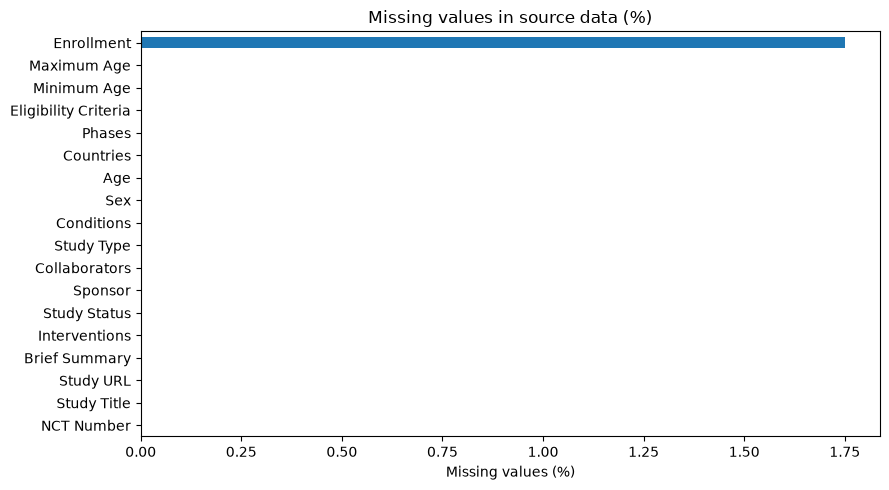

In [14]:
ax = missing_pct.sort_values().plot.barh(figsize=(9, 5), title="Missing values in source data (%)")
ax.set_xlabel("Missing values (%)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_missingness.png", dpi=160)
plt.show()

In [15]:
print("Duplicate NCT identifiers:", raw["NCT Number"].duplicated().sum())
print("Missing NCT identifiers:", raw["NCT Number"].isna().sum())
display(raw[["NCT Number", "Study Title"]].head())

Duplicate NCT identifiers: 0
Missing NCT identifiers: 0


,NCT Number,Study Title
0,NCT05429866,Immunological Variables Associated to ICI Toxicity in Cancer Patients
1,NCT01765556,A Pharmacokinetics Study to Investigate the Effect of Ketoconazole on Vemura...
2,NCT02399956,Lactation Outcomes Among Survivors of Pediatric Cancer
3,NCT03208556,Safety and Efficacy of iPD1 CD19 eCAR T Cells in Relapsed or Refractory B-ce...
4,NCT06133556,Conditioning Regimen Containing Melphalan and Cladribine for Refractory / Re...


In [16]:
invalid_id = ~raw["NCT Number"].astype("string").str.fullmatch(r"NCT\d{8}", na=False)
print("Invalid NCT identifiers:", int(invalid_id.sum()))
display(raw.loc[invalid_id, ["NCT Number", "Study Title"]].head())

Invalid NCT identifiers: 0


,NCT Number,Study Title


In [17]:
study_type_counts = raw["Study Type"].value_counts(dropna=False).rename_axis("Study Type").reset_index(name="count")
display(study_type_counts.head(15))

,Study Type,count
0,INTERVENTIONAL,7921
1,OBSERVATIONAL,2045
2,EXPANDED_ACCESS,34


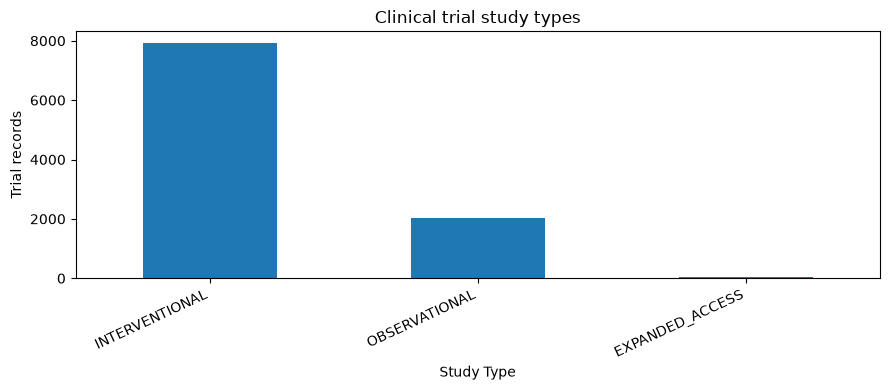

In [18]:
ax = study_type_counts.set_index("Study Type")["count"].plot.bar(figsize=(9, 4), title="Clinical trial study types")
ax.set_ylabel("Trial records")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_study_types.png", dpi=160)
plt.show()

In [19]:
status_counts = raw["Study Status"].value_counts(dropna=False).rename_axis("Study Status").reset_index(name="count")
display(status_counts.head(20))

,Study Status,count
0,COMPLETED,4298
1,UNKNOWN,1602
2,RECRUITING,1538
3,TERMINATED,928
4,ACTIVE_NOT_RECRUITING,639
5,NOT_YET_RECRUITING,510
6,WITHDRAWN,352
7,ENROLLING_BY_INVITATION,69
8,SUSPENDED,30
9,NO_LONGER_AVAILABLE,18


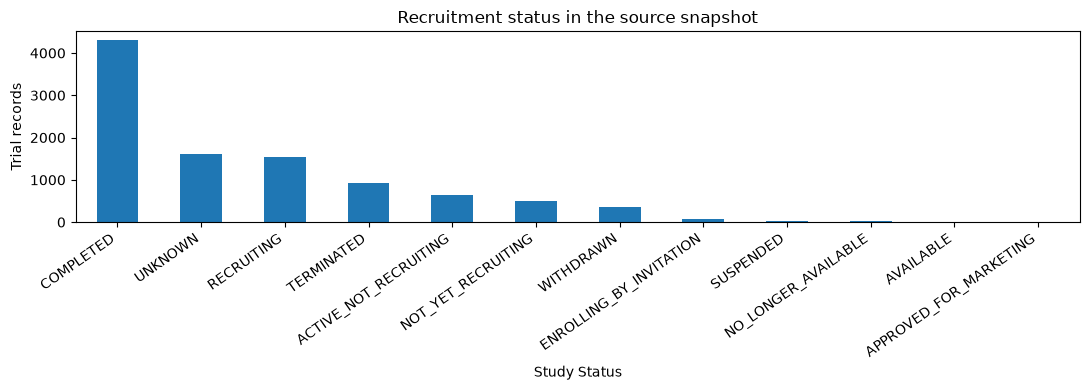

In [20]:
ax = status_counts.head(15).set_index("Study Status")["count"].plot.bar(figsize=(11, 4), title="Recruitment status in the source snapshot")
ax.set_ylabel("Trial records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_status.png", dpi=160)
plt.show()

In [21]:
interventional_status = pd.crosstab(raw["Study Type"], raw["Study Status"])
display(interventional_status.head(15))

Study Status,ACTIVE_NOT_RECRUITING,APPROVED_FOR_MARKETING,AVAILABLE,COMPLETED,ENROLLING_BY_INVITATION,NOT_YET_RECRUITING,NO_LONGER_AVAILABLE,RECRUITING,SUSPENDED,TERMINATED,UNKNOWN,WITHDRAWN
Study Type,,,,,,,,,,,,
EXPANDED_ACCESS,0,7,9,0,0,0,18,0,0,0,0,0
INTERVENTIONAL,535,0,0,3436,39,402,0,1188,24,853,1129,315
OBSERVATIONAL,104,0,0,862,30,108,0,350,6,75,473,37


In [22]:
sex_counts = raw["Sex"].value_counts(dropna=False).rename_axis("Sex").reset_index(name="count")
display(sex_counts.head(12))

,Sex,count
0,ALL,7896
1,FEMALE,1537
2,MALE,559
3,,8


In [23]:
age_counts = raw["Age"].value_counts(dropna=False).rename_axis("Age").reset_index(name="count")
display(age_counts.head(12))

,Age,count
0,"ADULT, OLDER_ADULT",8317
1,"CHILD, ADULT, OLDER_ADULT",831
2,"CHILD, ADULT",335
3,ADULT,317
4,CHILD,107
5,OLDER_ADULT,93


In [24]:
condition_terms = (
    raw["Conditions"].dropna().astype(str).str.split(r"\s*\|\s*").explode().str.strip()
)
top_conditions = condition_terms[condition_terms.ne("")].value_counts().head(20).rename_axis("Condition").reset_index(name="count")
display(top_conditions.head(20))

,Condition,count
0,Breast Cancer,740
1,Prostate Cancer,366
2,Cancer,337
3,Colorectal Cancer,295
4,Lung Cancer,252
5,Ovarian Cancer,177
6,Multiple Myeloma,169
7,Pancreatic Cancer,164
8,Head and Neck Cancer,154
9,Hepatocellular Carcinoma,147


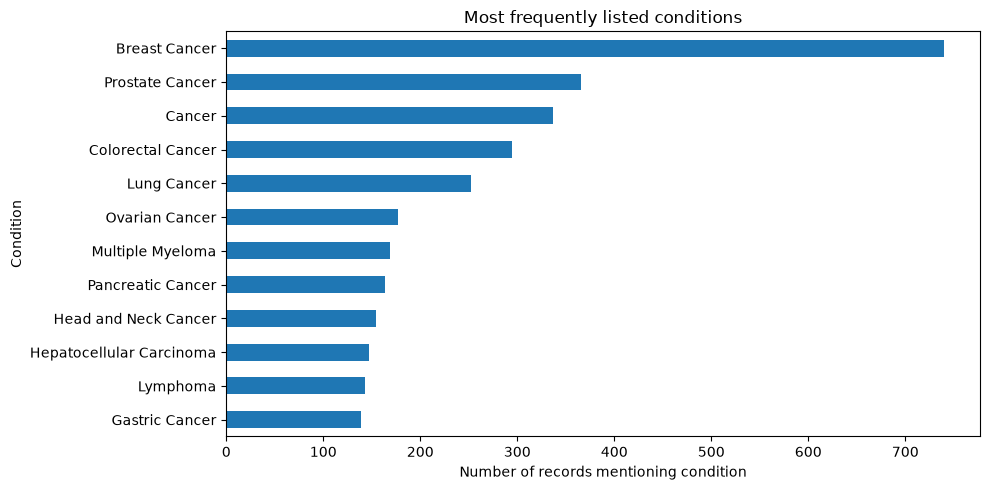

In [25]:
ax = top_conditions.head(12).iloc[::-1].set_index("Condition")["count"].plot.barh(figsize=(10, 5), title="Most frequently listed conditions")
ax.set_xlabel("Number of records mentioning condition")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_top_conditions.png", dpi=160)
plt.show()

In [26]:
intervention_items = raw["Interventions"].dropna().astype(str).str.split(r"\s*\|\s*").explode().str.strip()
intervention_types = intervention_items.str.extract(r"^([A-Za-z_ ]+):", expand=False).fillna("Unspecified")
top_intervention_types = intervention_types.value_counts().rename_axis("Intervention type").reset_index(name="count")
display(top_intervention_types.head(15))

,Intervention type,count
0,DRUG,10760
1,OTHER,2302
2,PROCEDURE,2198
3,BIOLOGICAL,1237
4,BEHAVIORAL,895
5,RADIATION,843
6,Unspecified,810
7,DEVICE,737
8,DIAGNOSTIC_TEST,485
9,DIETARY_SUPPLEMENT,184


In [27]:
summary_chars = raw["Brief Summary"].fillna("").astype(str).str.len()
display(summary_chars.describe().rename("summary_character_count").to_frame().head(10))

,summary_character_count
count,10000.000000
mean,650.228200
std,592.947872
min,22.000000
25%,258.000000
50%,441.000000
75%,824.000000
max,5019.000000


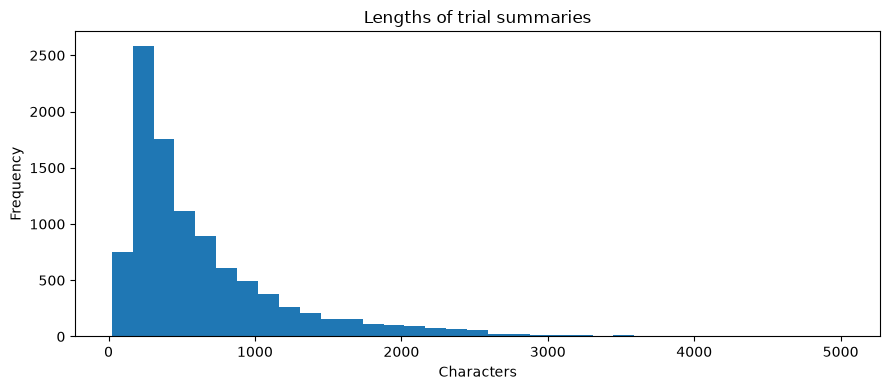

In [28]:
ax = summary_chars.plot.hist(bins=35, figsize=(9, 4), title="Lengths of trial summaries")
ax.set_xlabel("Characters")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_summary_lengths.png", dpi=160)
plt.show()

In [ ]:
optional_fields = ["Phases", "Enrollment", "Countries", "Eligibility Criteria", "Minimum Age", "Maximum Age"]
field_availability = pd.DataFrame([
    {"field": c, "present": c in raw.columns,
     "non_missing": int(raw[c].notna().sum()) if c in raw.columns else 0}
    for c in optional_fields
])
display(field_availability.head(12))

In [ ]:
prepared = raw.copy()
print("Copied raw data for cleaning:", prepared.shape)
display(prepared.head())

In [ ]:
for col in prepared.select_dtypes(include=["object", "string"]).columns:
    prepared[col] = prepared[col].map(lambda x: re.sub(r"\s+", " ", x).strip() if isinstance(x, str) else x)
display(prepared.head())

In [ ]:
prepared["NCT Number"] = prepared["NCT Number"].astype("string").str.upper().str.strip()
display(prepared[["NCT Number", "Study Title"]].head())

In [ ]:
rows_before_id_filter = len(prepared)
valid_nct = prepared["NCT Number"].str.fullmatch(r"NCT\d{8}", na=False)
prepared = prepared.loc[valid_nct].copy()
print("Records removed for invalid/missing NCT IDs:", rows_before_id_filter - len(prepared))
display(prepared.head())

In [ ]:
rows_before_dedup = len(prepared)
prepared = prepared.drop_duplicates(subset=["NCT Number"], keep="first").copy()
print("Duplicate study records removed:", rows_before_dedup - len(prepared))
display(prepared.head())

In [ ]:
prepared["Study Type"] = prepared["Study Type"].astype("string").str.upper().str.replace(" ", "_", regex=False)
display(prepared[["NCT Number", "Study Type"]].head())

In [ ]:
prepared["Study Status"] = prepared["Study Status"].astype("string").str.upper().str.replace(" ", "_", regex=False)
display(prepared[["NCT Number", "Study Status"]].head())

In [ ]:
rows_before_type_filter = len(prepared)
prepared = prepared.loc[prepared["Study Type"].eq("INTERVENTIONAL")].copy()
print("Removed non-interventional studies:", rows_before_type_filter - len(prepared))
print("Interventional studies retained:", len(prepared))
display(prepared.head())

In [ ]:
required_text_fields = ["Study Title", "Conditions", "Interventions", "Brief Summary"]
for col in required_text_fields:
    if col not in prepared.columns:
        prepared[col] = pd.NA
print("Text field availability:")
display(prepared[required_text_fields].isna().sum().to_frame("missing").head(10))

In [ ]:
prepared["conditions_clean"] = prepared["Conditions"].fillna("").astype(str).str.lower()
prepared["conditions_clean"] = prepared["conditions_clean"].str.replace(r"\btumours?\b", "tumor", regex=True)
display(prepared[["Conditions", "conditions_clean"]].head())

In [ ]:
prepared["interventions_clean"] = prepared["Interventions"].fillna("").astype(str).str.lower()
prepared["interventions_clean"] = prepared["interventions_clean"].str.replace(r"\btumours?\b", "tumor", regex=True)
display(prepared[["Interventions", "interventions_clean"]].head())

In [ ]:
prepared["title_clean"] = prepared["Study Title"].fillna("").astype(str).str.lower()
prepared["title_clean"] = prepared["title_clean"].str.replace(r"\btumours?\b", "tumor", regex=True)
display(prepared[["Study Title", "title_clean"]].head())

In [ ]:
prepared["summary_clean"] = prepared["Brief Summary"].fillna("").astype(str).str.lower()
prepared["summary_clean"] = prepared["summary_clean"].str.replace(r"\btumours?\b", "tumor", regex=True)
display(prepared[["Brief Summary", "summary_clean"]].head())

In [ ]:
prepared["model_text"] = (
    prepared["conditions_clean"] + " " +
    prepared["interventions_clean"] + " " +
    prepared["title_clean"] + " " +
    prepared["summary_clean"]
).str.replace(r"\s+", " ", regex=True).str.strip()
display(prepared[["NCT Number", "model_text"]].head())

In [ ]:
prepared["weighted_model_text"] = (
    prepared["conditions_clean"] + " " + prepared["conditions_clean"] + " " +
    prepared["interventions_clean"] + " " + prepared["interventions_clean"] + " " +
    prepared["title_clean"] + " " + prepared["summary_clean"]
).str.replace(r"\s+", " ", regex=True).str.strip()
display(prepared[["NCT Number", "weighted_model_text"]].head())

In [ ]:
prepared["text_length"] = prepared["model_text"].str.len()
display(prepared[["NCT Number", "text_length", "model_text"]].head())

In [ ]:
rows_before_text_filter = len(prepared)
prepared = prepared.loc[prepared["text_length"] >= 25].copy()
print("Removed trials with fewer than 25 combined text characters:", rows_before_text_filter - len(prepared))
display(prepared.head())

In [ ]:
prepared["Study URL"] = "https://clinicaltrials.gov/study/" + prepared["NCT Number"].astype(str)
display(prepared[["NCT Number", "Study URL"]].head())

In [ ]:
prepared["Sex"] = prepared["Sex"].astype("string").str.upper().str.strip()
display(prepared[["NCT Number", "Sex", "Age"]].head())

In [ ]:
prepared["is_recruiting"] = prepared["Study Status"].eq("RECRUITING").fillna(False)
display(prepared[["NCT Number", "Study Status", "is_recruiting"]].head())

In [ ]:
prepared["is_upcoming"] = prepared["Study Status"].eq("NOT_YET_RECRUITING").fillna(False)
display(prepared[["NCT Number", "Study Status", "is_upcoming"]].head())

In [ ]:
recruiting_catalogue = prepared.loc[prepared["is_recruiting"]].copy()
print("Recruiting trial records (snapshot):", len(recruiting_catalogue))
display(recruiting_catalogue[["NCT Number", "Study Title", "Study Status", "Study URL"]].head())

In [ ]:
upcoming_catalogue = prepared.loc[prepared["is_upcoming"]].copy()
print("Not-yet-recruiting trial records (not open for enrolment):", len(upcoming_catalogue))
display(upcoming_catalogue[["NCT Number", "Study Title", "Study Status"]].head())

In [ ]:
ready_counts = pd.DataFrame([
    ("Raw records", len(raw)),
    ("Valid NCT identifier + deduplicated", rows_before_type_filter),
    ("Interventional only", rows_before_text_filter),
    ("Text-ready interventional", len(prepared)),
    ("Recruiting-only search catalogue", len(recruiting_catalogue)),
    ("Not yet recruiting (separate catalogue)", len(upcoming_catalogue))
], columns=["Preparation milestone", "Records"])
display(ready_counts.head(10))

In [ ]:
prepared_missing = (prepared.isna().mean() * 100).sort_values(ascending=False)
display(prepared_missing.rename("missing_percent").to_frame().head(25))

In [ ]:
assert prepared["NCT Number"].is_unique
assert prepared["NCT Number"].notna().all()
assert prepared["Study Type"].eq("INTERVENTIONAL").all()
assert prepared["model_text"].str.len().ge(25).all()
assert recruiting_catalogue["Study Status"].eq("RECRUITING").all()
print("All Stage 3 data-quality checks passed.")
display(prepared[["NCT Number", "Study Title", "Study Status", "model_text"]].head())

In [ ]:
train_df, test_df = train_test_split(prepared, test_size=0.20, random_state=42)
print("Train / test records:", len(train_df), len(test_df))
display(train_df[["NCT Number", "model_text"]].head())

In [ ]:
assert set(train_df["NCT Number"]).isdisjoint(set(test_df["NCT Number"]))
print("No NCT identifier appears in both train and test sets.")
display(test_df[["NCT Number", "model_text"]].head())

In [ ]:
prepared.to_csv(OUTPUT_DIR / "interventional_trials_model_ready.csv", index=False)
print("Saved:", OUTPUT_DIR / "interventional_trials_model_ready.csv")
display(prepared[["NCT Number", "Study Status", "model_text"]].head())

In [ ]:
recruiting_catalogue.to_csv(OUTPUT_DIR / "recruiting_trials_search_catalogue.csv", index=False)
print("Saved:", OUTPUT_DIR / "recruiting_trials_search_catalogue.csv")
display(recruiting_catalogue[["NCT Number", "Study Status", "model_text"]].head())

In [ ]:
train_df.to_csv(OUTPUT_DIR / "training_trials.csv", index=False)
print("Saved training file")
display(train_df[["NCT Number", "model_text"]].head())

In [ ]:
test_df.to_csv(OUTPUT_DIR / "testing_trials.csv", index=False)
print("Saved testing file")
display(test_df[["NCT Number", "model_text"]].head())